# AP 155 Lab Exercise
---
## Exercise 10: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Tangaran, Grisby Paul James
- _Student No._: 2024-02777
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

### Problem 1: Exploring FT of varying waveforms

![Figure for Problem 1: Sine Wave](10-sinewave.png)
![Figure for Problem 1: Gaussian](10-gaussian.png)
![Figure for Problem 1: Dirac Delta](10-diracdelta.png)

**Figure 1. Fourier transforms of different waveforms.** Input signal (left), FT magnitude (middle), and FT phase (right) for a 2 Hz sine wave, a Gaussian pulse with σ = 1 centered at t = 5, and a Dirac delta at t = 5

Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?


---
* The shape of a signal in time decides which frequencies it is made of. The sine wave repeats at one steady rate, so its transform is a single sharp peak at 2 Hz, while the Dirac delta is one sudden spike that needs every frequency in equal amounts, so its transform is flat. The Gaussian falls in between, with a smooth bump centered at zero frequency, and sigma affects it in the opposite way: a larger sigma gives a wider, smoother pulse that only needs low frequencies, so its transform gets narrower, while a smaller sigma gives a sharper pulse whose transform gets wider. In short, the narrower a signal is in time, the wider it is in frequency, and the reverse is also true.


### Problem 2: Signal Processing in 1D 

![Figure for Problem 2: Signal Processing in 1D (N=25000)](10-orig_recovered25k.png)
![Figure for Problem 2: Signal Processing in 1D (N=5000)](10-orig_recovered5k.png)

**Figure 2. Signal recovery from noisy data.** Original (solid) and recovered (dashed) signals after applying a Hann window, removing frequencies below 60% of the highest peak, and taking the inverse FFT, for N = 25000 and N = 5000


Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)

---
* Lowering N does not change the three waves or the 5000 Hz sampling rate; it only makes the recording shorter (N = 5000 is just 1 second), so fewer cycles are captured and each frequency peak becomes smaller compared to the noise. With N = 5000, the original signal can no longer be recovered well: the recovered curve becomes jagged and swings far past the true wave, and the RMS error rises from about 0.60 to about 3.06, because many noise peaks now pass the 60% threshold and get added back into the signal. There is a limit because the real peaks grow in proportion to N while the noise only grows with √N, so for this noise level and threshold, the peaks stop standing out clearly below roughly N = 10000.


### Problem 3: Aliasing

![Figure for Problem 3: Aliasing](10-aliasing.png)

**Figure 3. Sampling above and below the Nyquist rate.** A 9 Hz sine wave sampled at 100 Hz (top, no aliasing) and 12 Hz (bottom, aliased), showing the samples over the real signal (left), the FT magnitude (middle), and the FT phase (right)

Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

---
* The signal being sampled is a 9 Hz sine wave, so it must be sampled faster than 2 × 9 = 18 Hz (the Nyquist rate) to avoid aliasing. In the top row, the sampling frequency is 100 Hz, well above 18 Hz, so the samples follow the real wave closely and the Fourier transform shows a single peak at the correct 9 Hz. In the bottom row, the sampling frequency is only 12 Hz, below 18 Hz, so the samples are too far apart and connect into a slow wave that does not match the real one, and the transform shows a false peak at 3 Hz instead. This means the two transforms are not the same: sampling too slowly makes the 9 Hz wave appear as a |9 − 12| = 3 Hz wave, which is called aliasing.



### Other comments
- None

---
## Section 2: Code

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

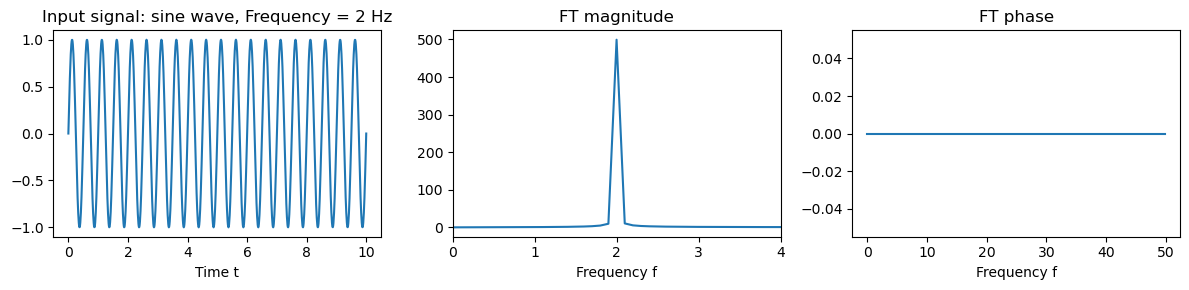

In [21]:
# Signal parameters
N = 1000                      # Number of sample points
t = np.linspace(0, 10, N)     # Time vector from 0 to 10 seconds
deltaT = t[1] - t[0]          # Sampling interval

f = 2                         # Sine wave frequency in Hz
x = np.sin(2 * np.pi * f * t) # 2 Hz sine wave signal

# Fourier transform calculation
freqs = np.fft.fftfreq(N, deltaT)  
x_ft = np.fft.fft(x)               

# Center zero-frequency component
freqs = np.fft.fftshift(freqs)
x_ft = np.fft.fftshift(x_ft)

# Magnitude and phase spectra
x_mag = np.abs(x_ft)
x_phase = np.unwrap(np.angle(x_mag)) 

pos = freqs >= 0                    # Mask for non-negative frequencies

# Plotting signal, FT magnitude, and FT phase
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Input signal: sine wave, Frequency = 2 Hz")
ax[0].set_xlabel("Time t")
ax[0].plot(t, x)

ax[1].set_title("FT magnitude")
ax[1].set_xlabel("Frequency f")
ax[1].plot(freqs[pos], x_mag[pos])
ax[1].set_xlim(0, 4)

ax[2].set_title("FT phase")
ax[2].set_xlabel("Frequency f")
ax[2].plot(freqs[pos], x_phase[pos])

fig.tight_layout()
plt.savefig("10-sinewave.png")
plt.show()

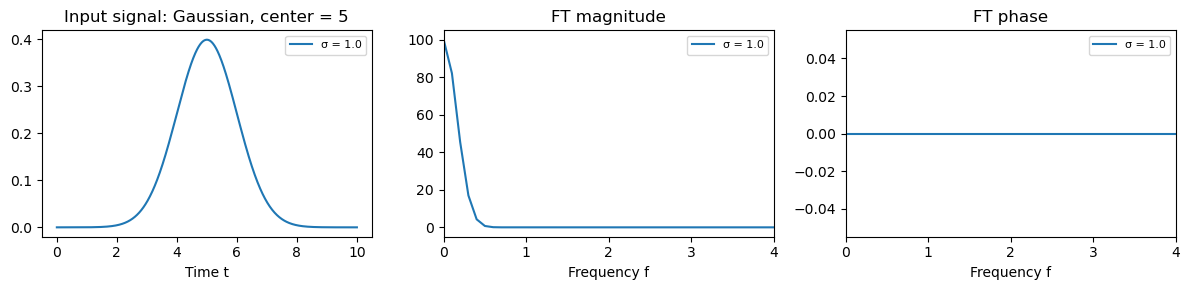

In [22]:
# Signal parameters
N = 1000
t = np.linspace(0, 10, N)
deltaT = t[1] - t[0]

t0 = 5                        # Center time of Gaussian pulse
sigma = 1.0                   # Standard deviation (width) of Gaussian

freqs = np.fft.fftfreq(N, deltaT)
freqs = np.fft.fftshift(freqs)
pos = freqs >= 0

# Normalized Gaussian temporal waveform
x = 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-(t - t0)**2 / (2 * sigma**2))

# Fourier transform and spectral shifts
x_ft = np.fft.fft(x)
x_ft = np.fft.fftshift(x_ft)

x_mag = np.abs(x_ft)
x_phase = np.unwrap(np.angle(x_mag))

# Plotting signal, FT magnitude, and FT phase
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].plot(t, x, label=f"σ = {sigma}")
ax[0].set_title("Input signal: Gaussian, center = 5")
ax[0].set_xlabel("Time t")

ax[1].plot(freqs[pos], x_mag[pos], label=f"σ = {sigma}")
ax[1].set_title("FT magnitude")
ax[1].set_xlabel("Frequency f")
ax[1].set_xlim(0, 4)

ax[2].plot(freqs[pos], x_phase[pos], label=f"σ = {sigma}")
ax[2].set_title("FT phase")
ax[2].set_xlabel("Frequency f")
ax[2].set_xlim(0, 4)

for a in ax:
    a.legend(fontsize=8)

fig.tight_layout()
plt.savefig("10-gaussian.png")
plt.show()

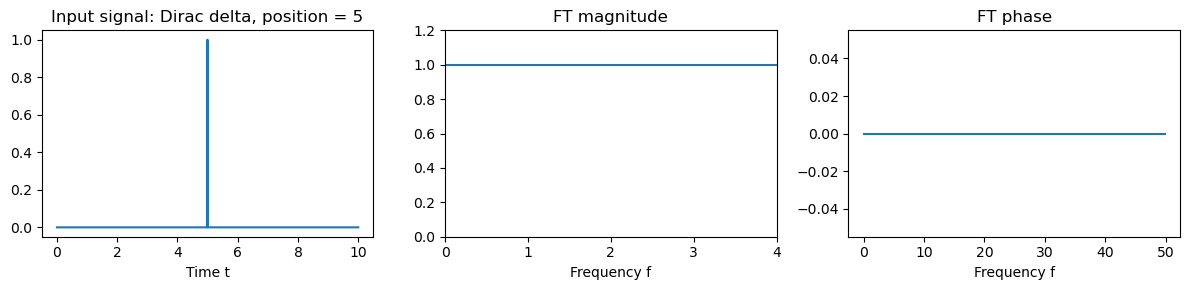

In [23]:
# Signal parameters
N = 1000
t = np.linspace(0, 10, N)
deltaT = t[1] - t[0]

t0 = 5                        # Position of impulse
x = np.zeros(N)
x[np.argmin(np.abs(t - t0))] = 1 # Discrete approximation of Dirac delta impulse

# Frequency computation and FFT
freqs = np.fft.fftfreq(N, deltaT)
x_ft = np.fft.fft(x)

freqs = np.fft.fftshift(freqs)
x_ft = np.fft.fftshift(x_ft)

x_mag = np.abs(x_ft)
x_phase = np.unwrap(np.angle(x_mag))
pos = freqs >= 0

# Plotting impulse signal, FT magnitude, and FT phase
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Input signal: Dirac delta, position = 5")
ax[0].set_xlabel("Time t")
ax[0].plot(t, x)

ax[1].set_title("FT magnitude")
ax[1].set_xlabel("Frequency f")
ax[1].plot(freqs[pos], x_mag[pos])
ax[1].set_xlim(0, 4)
ax[1].set_ylim(0, 1.2)

ax[2].set_title("FT phase")
ax[2].set_xlabel("Frequency f")
ax[2].plot(freqs[pos], x_phase[pos])

fig.tight_layout()
plt.savefig("10-diracdelta.png")
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [66]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 25000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]


signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

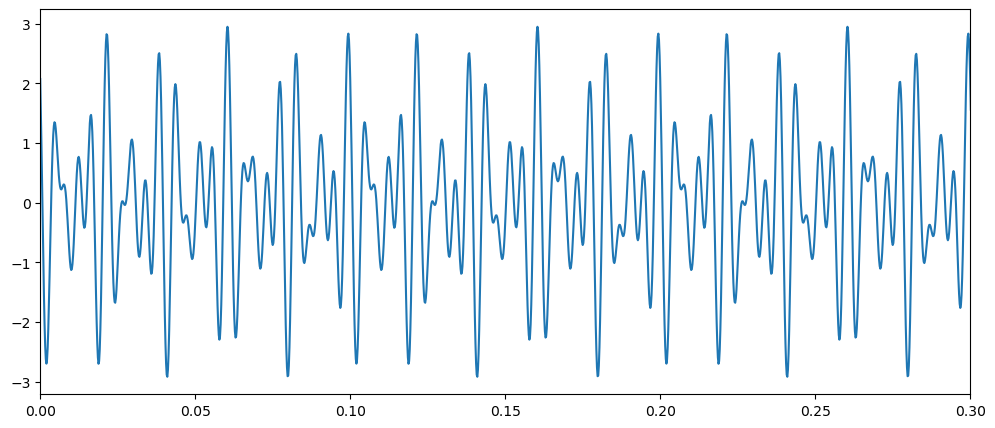

In [67]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)

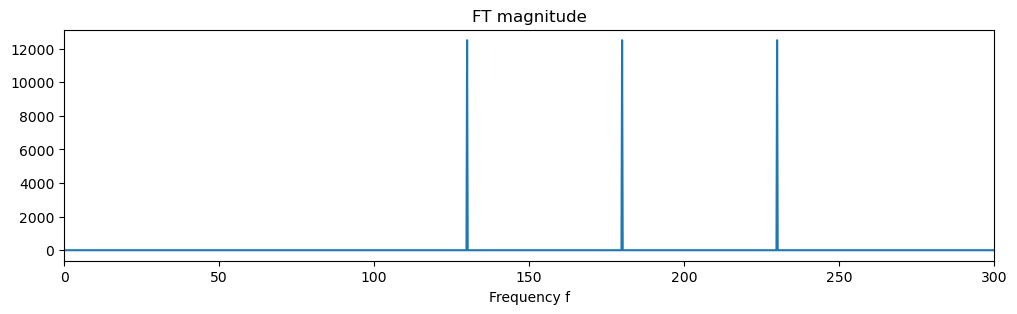

In [68]:
#FILL: Plot the fourier transform of the clean, original signal
freq_axis = np.fft.fftfreq(N, dt)    
clean_ft = np.fft.fft(signal_original)

freq_axis = np.fft.fftshift(freq_axis)
clean_ft = np.fft.fftshift(clean_ft)

clean_mag = np.abs(clean_ft)

pos = freq_axis >= 0                 

fig, ax = plt.subplots(figsize=(12, 3))
ax.set_title("FT magnitude")
ax.set_xlabel("Frequency f")
ax.plot(freq_axis[pos], clean_mag[pos])
ax.set_xlim(0, 300)                  

plt.show()

In [69]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

(0.0, 0.3)

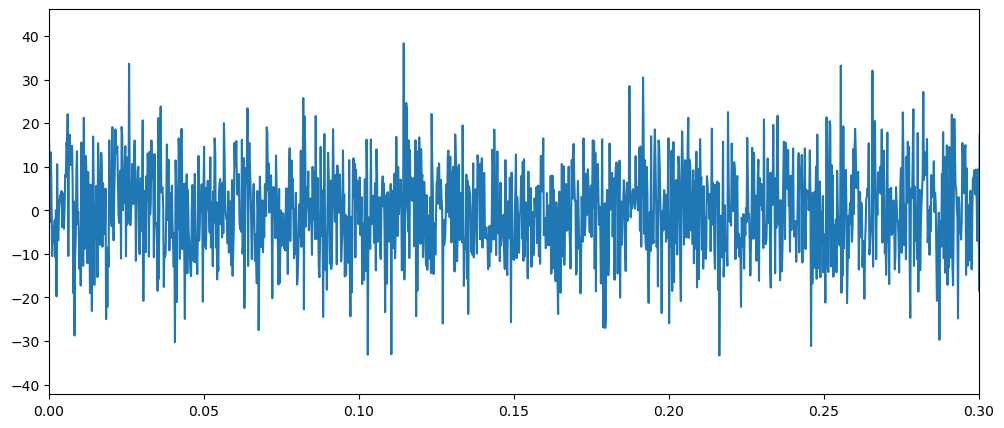

In [70]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)

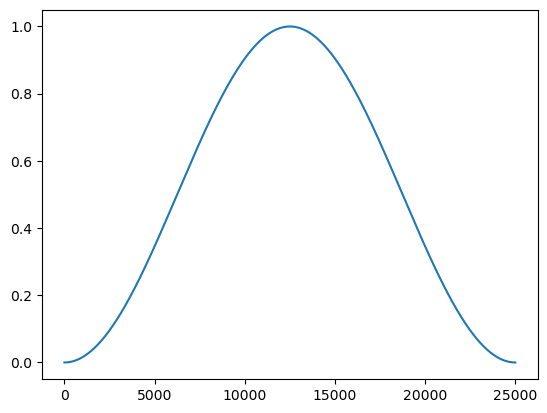

In [71]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)

In [72]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))


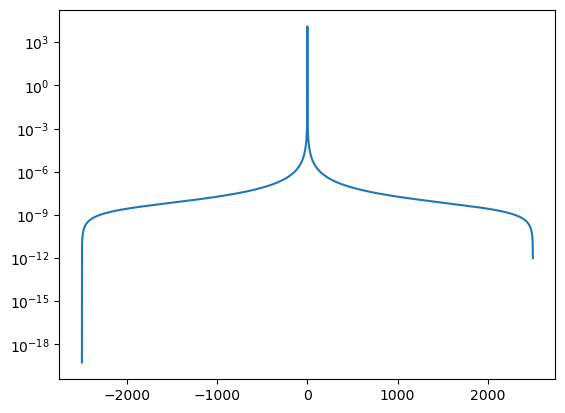

In [73]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

In [74]:
noisyFourier = np.fft.fft(noisy_data*window)

noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))


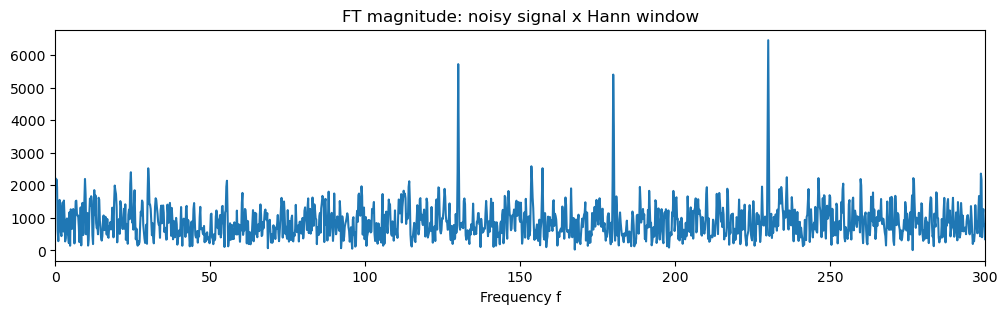

In [75]:
# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window
noisy_mag = np.abs(np.fft.fftshift(noisyFourier))   

fig, ax = plt.subplots(figsize=(12, 3))
ax.set_title("FT magnitude: noisy signal x Hann window")
ax.set_xlabel("Frequency f")
ax.plot(freq_axis[pos], noisy_mag[pos])
ax.set_xlim(0, 300)

plt.show()

In [76]:
# Fill: Find a suitable threshold value to filter the noise in fourier space
threshold = 0.6 * np.abs(noisyFourier).max()       

filteredFourier = noisyFourier.copy()               # copy so the original stays unchanged
filteredFourier[np.abs(noisyFourier) < threshold] = 0   # set everything below the threshold to 0 (the noise)

kept_freqs = np.fft.fftfreq(N, dt)[filteredFourier != 0]

print("Frequencies kept:", kept_freqs)
print("Positive frequencies kept:", kept_freqs[kept_freqs > 0])

Frequencies kept: [ 130.  180.  230. -230. -180. -130.]
Positive frequencies kept: [130. 180. 230.]


In [77]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain
recoveredSignal = np.real(np.fft.ifft(filteredFourier))   
recoveredSignal = recoveredSignal / window.mean()        

RMS error = 0.14924


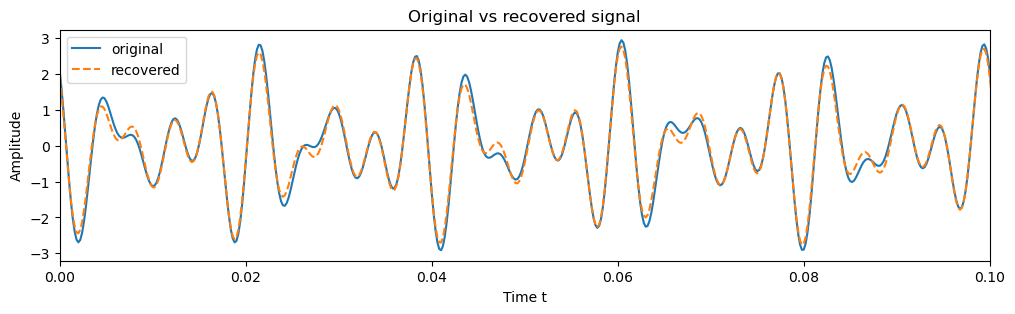

In [79]:
# Plot the recovered signal
# fig, ax = plt.subplots(figsize= (12,5))
# ax.plot(t_, recoveredSignal)
# ax.set_xlim(0,0.3)
error = np.sqrt(np.mean((recoveredSignal - signal_original)**2))   # root mean square error
print(f"RMS error = {error:.5f}")

fig, ax = plt.subplots(figsize=(12, 3))
ax.set_title("Original vs recovered signal")
ax.set_xlabel("Time t")
ax.set_ylabel("Amplitude")
ax.plot(t_, signal_original, label="original")
ax.plot(t_, recoveredSignal, "--", label="recovered")
ax.set_xlim(0, 0.1)
ax.legend()
plt.savefig("10-orig_recovered25k.png", bbox_inches='tight')
plt.show()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

fs = 100 Hz (Above Nyquist frequency (No Aliasing)): peak at 9.00 Hz


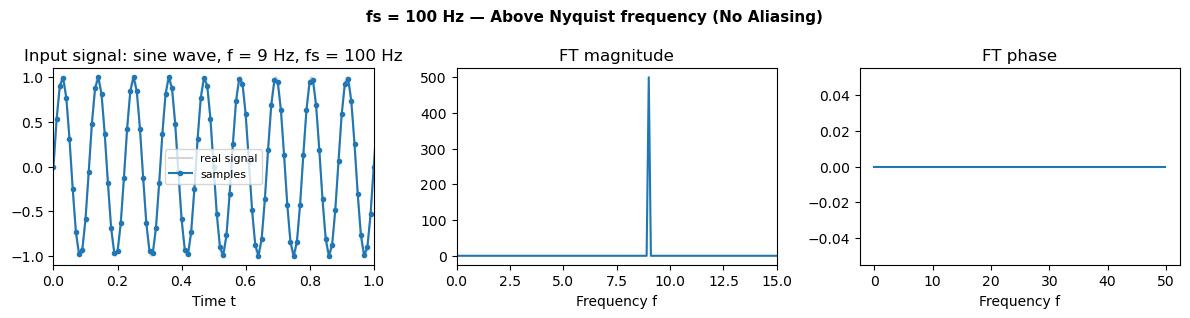

fs = 12 Hz (Below Nyquist frequency (Aliased)): peak at 3.00 Hz


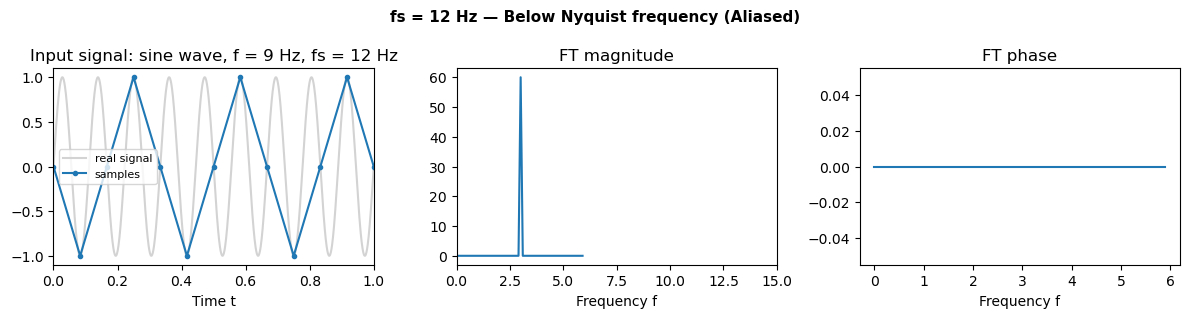

In [38]:
f = 9                                    # Target sine wave frequency in Hz               
T = 10                                    
fs_list = [100, 12]                      # Nyquist frequency, 100>2*9 hz, 12<2*9 hz

t_fine = np.linspace(0, T, 10000)        
x_real = np.sin(2*np.pi*f*t_fine)        # Continuous 9 Hz sine wave

for fs in fs_list:
    f_nyquist = 2 * f
    # Evaluate Nyquist criterion (f_s > 2 * f_max)
    if fs > f_nyquist:
        nyq_label = "Above Nyquist frequency (No Aliasing)"
    else:
        nyq_label = "Below Nyquist frequency (Aliased)"

    # Discrete sampling se
    N = int(T * fs)                          
    t = np.linspace(0, T, N, endpoint=False) 
    deltaT = t[1] - t[0]                      

    # Sampled discrete signal
    x = np.sin(2 * np.pi * f * t)                  

    freqs = np.fft.fftfreq(N, deltaT)        
    x_ft = np.fft.fft(x)

    freqs = np.fft.fftshift(freqs)
    x_ft = np.fft.fftshift(x_ft)

    x_mag = np.abs(x_ft)
    x_phase = np.angle(x_mag)  
    x_phase = np.unwrap(x_phase)

    pos = freqs >= 0

    print(f"fs = {fs} Hz ({nyq_label}): peak at {freqs[pos][np.argmax(x_mag[pos])]:.2f} Hz")

    fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))

    fig.suptitle(f"fs = {fs} Hz — {nyq_label}", fontsize=11, fontweight="bold")

    ax[0].set_title(f"Input signal: sine wave, f = {f} Hz, fs = {fs} Hz")
    ax[0].set_xlabel("Time t")
    ax[0].plot(t_fine, x_real, color="lightgray", label="real signal")
    ax[0].plot(t, x, ".-", label="samples")
    ax[0].set_xlim(0, 1)
    ax[0].legend(fontsize=8)

    ax[1].set_title("FT magnitude")
    ax[1].set_xlabel("Frequency f")
    ax[1].plot(freqs[pos], x_mag[pos])
    ax[1].set_xlim(0, 15)

    ax[2].set_title("FT phase")
    ax[2].set_xlabel("Frequency f")
    ax[2].plot(freqs[pos], x_phase[pos])

    fig.tight_layout()
    plt.savefig(f"10-aliasing_{fs}.png")
    plt.show()

#### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

-----------

**Problem 1.** This code computes and visualizes the Fourier transforms of a sine wave, a Gaussian pulse, and a Dirac delta impulse in 1×3 subplots. Each signal undergoes a standardized Fast Fourier Transform workflow (`fftfreq` → `fft` → `fftshift`), evaluating magnitude and phase directly from the transform array to enable direct spectral comparison. Only non-negative frequencies ($f \ge 0$) are plotted, taking advantage of the symmetry inherent to real-valued signals to eliminate redundant negative-frequency data.

**Problem 2.** This code performs 1D signal denoising on a multi-tone signal (130, 180, and 230 Hz) mixed with many Gaussian noise. A Hann window is applied prior to FFT computation to minimize spectral leakage caused by finite sampling boundaries. Because the signal energy is concentrated in sharp spectral peaks while broadband noise is distributed across all bins, applying a 60% relative amplitude threshold cleanly isolates the true signal components for accurate time-domain reconstruction via Inverse FFT (IFFT).

**Problem 3.** This code demonstrates sampling theory and aliasing by processing a 9 Hz sine wave sampled at $f_s = 100\text{ Hz}$ (above the $18\text{ Hz}$ Nyquist rate) and $f_s = 12\text{ Hz}$ (below Nyquist rate) within a loop. A high-resolution reference signal ($10,000$ points) is overlaid in the time-domain plots to visually illustrate the loss of continuous wave information during undersampling. The algorithm prints the dominant spectral peak location, confirming that undersampling at $12\text{ Hz}$ folds the 9 Hz signal to an apparent alias frequency of $|9 - 12| = 3\text{ Hz}$.

---
## Section 3: Notes

In [15]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

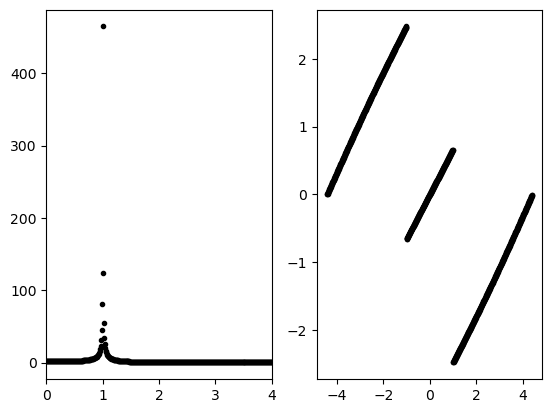

In [9]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [17]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

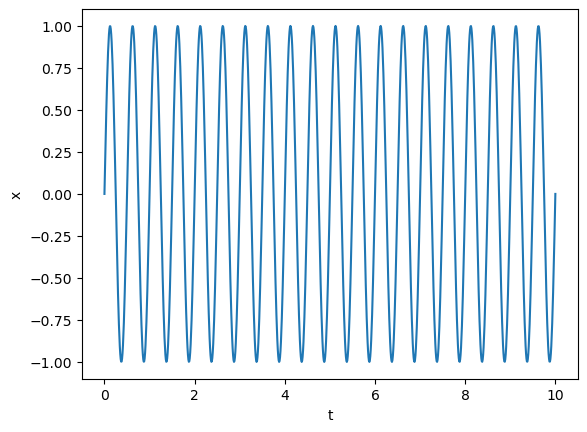

In [18]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [19]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

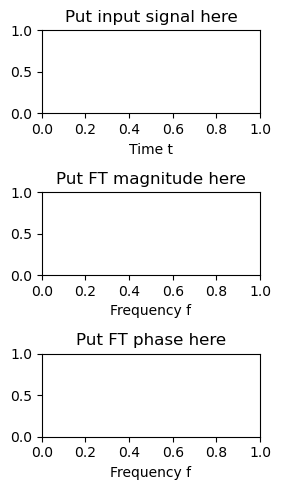

In [20]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

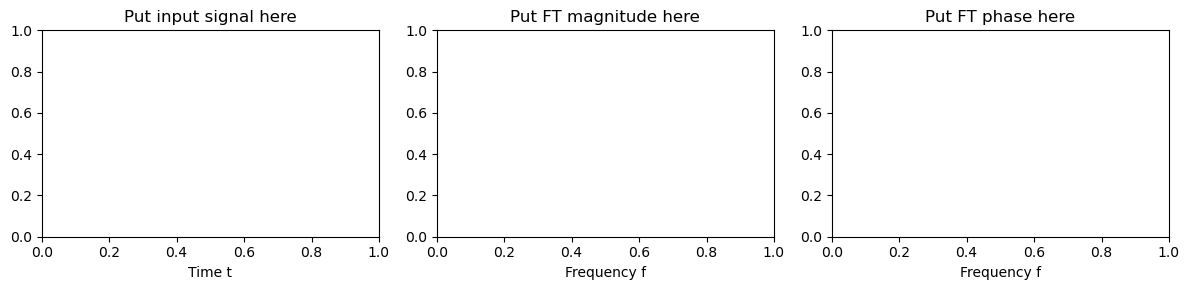

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

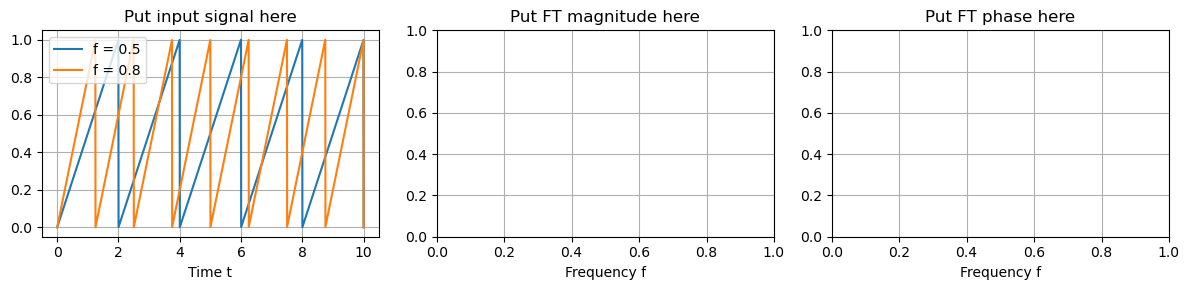

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [23]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



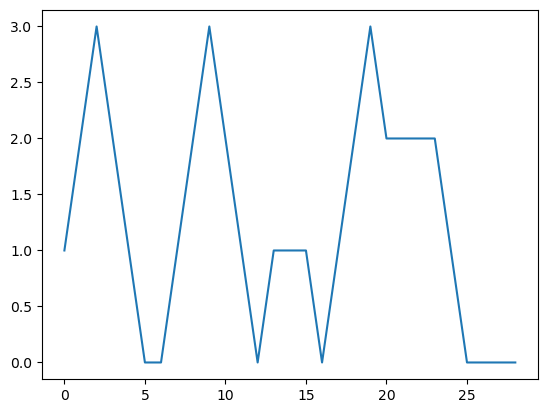

In [24]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [18]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [19]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

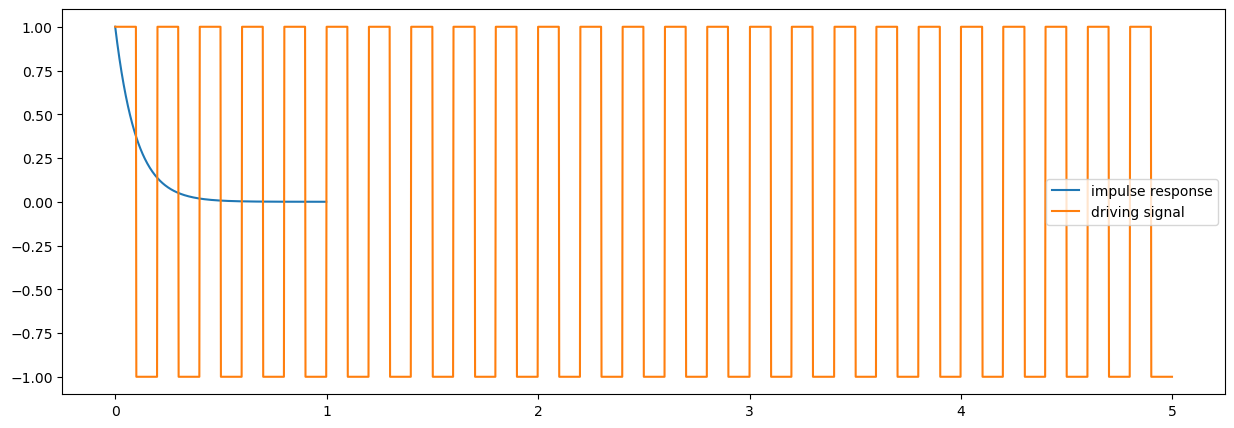

In [20]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [21]:
response = np.convolve(input_signal, h_t, mode = "same")

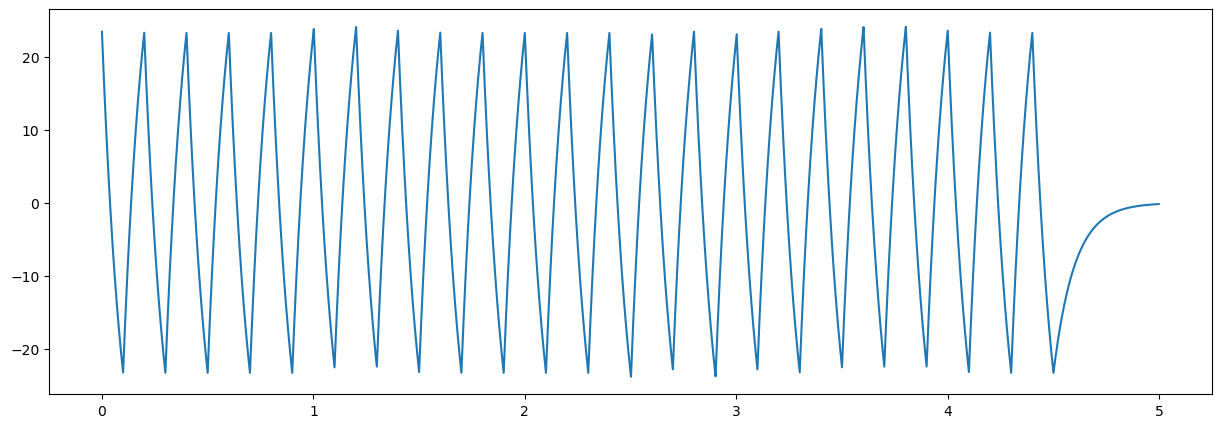

In [22]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [23]:
fourier_length = len(h_t) + len(input_signal) - 1

In [24]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [25]:
fourier_response = fourier_h*fourier_input 

In [26]:
response = np.real(np.fft.ifft(fourier_response))

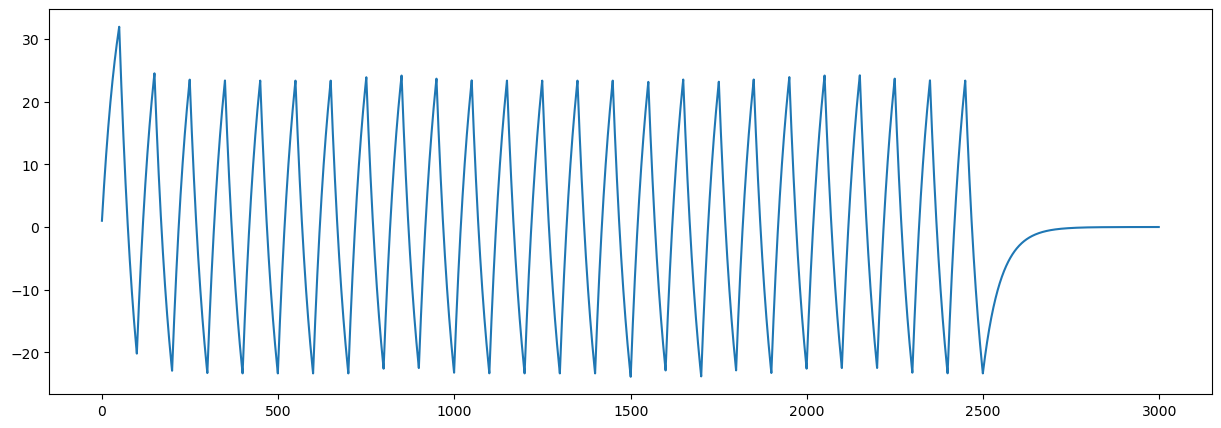

In [27]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)